# 06 - Huấn luyện RL self-play (cấp 6)

Phụ trách: Người 3. Thay cho `train/train_rl.py` cũ: toàn bộ logic nằm trong notebook để theo dõi quá trình train.

**Ý tưởng (policy gradient / REINFORCE có baseline)**: mạng tự chơi với chính nó, mỗi nước **lấy mẫu** từ phân phối policy (không phải luôn chọn max).
Cuối ván, mọi nước của bên thắng được "khuyến khích" và mọi nước của bên thua bị "làm giảm xác suất".

Chi tiết một bước cập nhật:
1. Self-play `EPISODES_PER_UPDATE` ván song song. Reward chỉ ở cuối ván: +1 thắng / 0 hòa / -1 thua (theo góc nhìn từng bên).
2. Return của mỗi nước `G = reward_cuối * gamma^(số nước còn lại)` (với gamma = 1 thì `G` = reward cuối).
3. Advantage `A = G - V(s)`: `V(s)` là đầu value của mạng, đóng vai **baseline** để giảm phương sai (không truyền gradient qua `A`).
4. `loss = -mean(log π(a|s) · A) + value_loss_coef · MSE(V, G) - entropy_coef · mean(entropy)`.
   Số hạng entropy giữ policy không co cụm quá sớm (khám phá).

Cứ `every_episodes` ván, mạng đang train (đi argmax) đấu các đối thủ cố định → **learning curve**. Đánh giá dùng seed riêng (`seed_base: 900`),
không trùng seed tune (100-102) và seed đánh giá cuối (0-2).

In [1]:
import json, os, platform, random, sys, tempfile, time
from pathlib import Path

# Chạy từ thư mục notebooks/ hay thư mục gốc đều được: luôn chuyển về thư mục gốc repo để đường dẫn trong config đúng.
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import yaml
from IPython.display import clear_output, display

from agents.nn_agent import NNAgent
from agents.registry import build_agent_by_name, is_available
from eval.tournament import play_game, random_opening
from models.nets import (build_model, count_params, legal_mask_from_actions, load_checkpoint, masked_logits,
                         save_checkpoint)
from othello.encoding import BLACK, encode_planes, index_to_action
from othello.game import OthelloGame

# QUICK_TEST = True: chạy thử cả notebook trong vài giây với dữ liệu/số vòng rất nhỏ, ghi ra thư mục tạm
# (để kiểm tra mọi thứ chạy được trước khi chạy thật). Chạy chính thức: để False.
QUICK_TEST = False

## 1. Cấu hình
Lấy từ `configs/train_rl.yaml`. Sửa trực tiếp ở ô này để thử nghiệm. Mỗi lần chạy chính thức đặt `RUN_NAME` **mới**.

In [2]:
with open(REPO / "configs" / "train_rl.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
tcfg, ecfg, exp, out = cfg["train"], cfg["eval"], cfg["exploration"], cfg["output"]
assert cfg["method"] == "policy_gradient" and exp["type"] == "policy_sampling", \
    "Notebook này cài policy_gradient + policy_sampling (epsilon-greedy chỉ hợp DQN)"

SEED = int(cfg["seed"])
EPISODES = int(cfg["episodes"])                         # tổng số ván self-play
EPISODES_PER_UPDATE = int(tcfg["episodes_per_update"])  # số ván gom cho mỗi bước gradient
OPENING_PLIES = int(cfg["self_play"]["opening_plies"])  # số nước đầu ngẫu nhiên để các ván khác nhau
TEMPERATURE = float(exp["temperature"])                 # lấy mẫu từ softmax(logit / T)
ENTROPY_COEF = float(exp["entropy_coef"])
LR, GAMMA = float(tcfg["lr"]), float(tcfg["gamma"])
REWARD = cfg["reward"]                                  # {"win": 1, "draw": 0, "loss": -1}
EVAL_EVERY, EVAL_GAMES = int(ecfg["every_episodes"]), int(ecfg["games"])
EVAL_SEED_BASE = int(ecfg["seed_base"])
CKPT_EVERY = int(cfg["checkpoint_every"])
OPPONENTS = list(ecfg["opponents"])
FROM_SCRATCH = False                                    # True = không nạp checkpoint supervised
INIT_FROM = REPO / cfg["init_from"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() and tcfg.get("device", "auto") == "auto" else "cpu")
RUN_NAME = f"rl_seed{SEED}"                             # tên thư mục log: ĐỔI cho mỗi lần chạy chính thức
CKPT_PATH = REPO / out["checkpoint_dir"] / out["checkpoint_name"]
LOG_DIR = REPO / out["log_dir"] / RUN_NAME

if QUICK_TEST:   # chạy thử nhanh: ít ván, từ đầu, đối thủ đơn giản, ghi ra thư mục tạm
    tmp = Path(tempfile.mkdtemp())
    EPISODES, EPISODES_PER_UPDATE, EVAL_EVERY, EVAL_GAMES, CKPT_EVERY = 32, 8, 16, 4, 16
    FROM_SCRATCH, OPPONENTS = True, ["random"]
    CKPT_PATH, LOG_DIR = tmp / "rl.pt", tmp / "log"

if LOG_DIR.exists() and any(LOG_DIR.iterdir()):
    raise FileExistsError(f"{LOG_DIR} đã có log. Đổi RUN_NAME (không ghi đè log thô).")
print(f"{EPISODES} ván self-play, {EPISODES_PER_UPDATE} ván/lần cập nhật, eval mỗi {EVAL_EVERY} ván ({EVAL_GAMES} ván/đối thủ), device={DEVICE}")

20000 ván self-play, 16 ván/lần cập nhật, eval mỗi 1000 ván (100 ván/đối thủ), device=cpu


## 2. Hàm self-play, cập nhật và đánh giá

- `self_play_batch`: chơi nhiều ván **cùng lúc** (mỗi lượt gom các thế cờ của mọi ván thành 1 lô để forward một lần → nhanh hơn nhiều).
  Mỗi nước do mạng chọn được ghi lại cùng return của nó. Các nước khai cuộc ngẫu nhiên **không** được học.
- `policy_gradient_update`: một bước REINFORCE có baseline trên toàn bộ nước của các ván vừa chơi (công thức ở đầu notebook).
- `evaluate_vs`: mạng (argmax) đấu một đối thủ cố định; mỗi cặp ván cùng khai cuộc, đổi màu. Seed cố định nên mọi lần đánh giá dùng
  cùng khai cuộc → các điểm trên đường cong so sánh được với nhau.

In [3]:
SEED_STRIDE = 1_000_000


def self_play_batch(model, n_games, opening_plies, temperature, rng, gen, device, reward_cfg, gamma):
    """Chơi n_games ván self-play song song. Trả về (lô mẫu, thống kê ván)."""
    games = []
    for _ in range(n_games):
        g = OthelloGame()
        for _ in range(opening_plies):                       # khai cuộc ngẫu nhiên (không phải mẫu học)
            if g.is_terminal():
                break
            g.step(rng.choice(g.legal_actions()))
        games.append(g)

    traj = [[] for _ in games]                               # mỗi bước: (planes, mặt nạ, nước đã chọn, người đi)
    active = [i for i, g in enumerate(games) if not g.is_terminal()]
    model.eval()
    while active:
        planes = np.stack([encode_planes(games[i].board, games[i].current_player) for i in active])
        masks = np.stack([legal_mask_from_actions(games[i].legal_actions()) for i in active])
        with torch.no_grad():
            logits, _ = model(torch.from_numpy(planes).to(device))
            logits = masked_logits(logits, torch.from_numpy(masks).to(device)) / temperature
            probs = torch.softmax(logits, dim=1).cpu()
        picks = torch.multinomial(probs, 1, generator=gen).squeeze(1).tolist()    # LẤY MẪU (khám phá)
        for j, i in enumerate(active):
            traj[i].append((planes[j], masks[j], picks[j], games[i].current_player))
            games[i].step(index_to_action(picks[j]))
        active = [i for i in active if not games[i].is_terminal()]

    P, M, A, G = [], [], [], []
    black_wins = draws = 0
    lengths = []
    for g, steps in zip(games, traj):
        res_black = g.result(BLACK)
        black_wins += res_black == 1
        draws += res_black == 0
        lengths.append(len(steps))
        for t, (pl, mk, a, player) in enumerate(steps):
            outcome = res_black * player                     # +1 thắng / 0 hòa / -1 thua theo góc nhìn bên đi
            r = {1: reward_cfg["win"], 0: reward_cfg["draw"], -1: reward_cfg["loss"]}[outcome]
            P.append(pl); M.append(mk); A.append(a)
            G.append(r * gamma ** (len(steps) - 1 - t))      # return: reward cuối chiết khấu theo số nước còn lại
    batch = None
    if P:
        batch = {"planes": torch.from_numpy(np.stack(P)).to(device), "legal": torch.from_numpy(np.stack(M)).to(device),
                 "action": torch.tensor(A, dtype=torch.long, device=device),
                 "ret": torch.tensor(G, dtype=torch.float32, device=device)}
    stats = {"mean_len": float(np.mean(lengths)) if lengths else 0.0,
             "black_win_rate": black_wins / n_games, "draw_rate": draws / n_games}
    return batch, stats


def policy_gradient_update(model, opt, batch, normalize_advantage=True, value_loss_coef=0.5, grad_clip=1.0,
                           entropy_coef=0.0):
    """Một bước REINFORCE có baseline trên toàn lô. Trả về dict thống kê."""
    model.train()
    logits, value = model(batch["planes"])
    logp_all = F.log_softmax(masked_logits(logits, batch["legal"]), dim=1)
    logp = logp_all.gather(1, batch["action"].unsqueeze(1)).squeeze(1)       # log π(a|s) của nước đã đi
    adv = (batch["ret"] - value).detach()                    # A = G - V(s); detach: baseline không nhận gradient policy
    if normalize_advantage and len(adv) > 1:
        adv = (adv - adv.mean()) / (adv.std() + 1e-8)
    policy_loss = -(logp * adv).mean()
    value_loss = F.mse_loss(value, batch["ret"])
    entropy = -(logp_all.exp() * logp_all).sum(1).mean()     # ô bất hợp lệ có xác suất 0 nên không đóng góp
    loss = policy_loss + value_loss_coef * value_loss - entropy_coef * entropy
    opt.zero_grad()
    loss.backward()
    grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
    opt.step()
    return {"policy_loss": policy_loss.item(), "value_loss": value_loss.item(), "entropy": entropy.item(),
            "grad_norm": float(grad_norm), "n_samples": len(adv)}


def evaluate_vs(model, opponent_name, n_games, seed_base):
    """Mạng (argmax) đấu `opponent_name` n_games ván, chia đều Đen/Trắng, cặp ván cùng khai cuộc."""
    wins = draws = losses = 0
    model.eval()
    for pair in range(n_games // 2):
        base = seed_base * SEED_STRIDE + pair * 10
        opening = random_opening(base + 3, 4)
        for learner_black in (True, False):
            learner = NNAgent(model=model, temperature=0.0, name="learner")
            opp = build_agent_by_name(opponent_name, seed=base + 2)
            black, white = (learner, opp) if learner_black else (opp, learner)
            rec = play_game(black, white, None, None, opening)
            outcome = rec["result_black"] * (1 if learner_black else -1)
            wins, draws, losses = wins + (outcome == 1), draws + (outcome == 0), losses + (outcome == -1)
    n = wins + draws + losses
    return {"games": n, "wins": int(wins), "draws": int(draws), "losses": int(losses),
            "score": (wins + 0.5 * draws) / n if n else float("nan")}


def show_progress(train_df, curve_df):
    """Vẽ lại chẩn đoán huấn luyện + learning curve (xóa hình cũ) sau mỗi lần đánh giá."""
    clear_output(wait=True)
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    w = max(1, len(train_df) // 10)
    ax[0].plot(train_df.episodes, train_df.entropy.rolling(w, min_periods=1).mean()); ax[0].set_title("Entropy policy")
    ax[1].plot(train_df.episodes, train_df.value_loss.rolling(w, min_periods=1).mean()); ax[1].set_title("Value loss")
    for opp, g in curve_df.groupby("opponent", sort=False):
        ax[2].plot(g.episodes, g.score, marker="o", label=opp)
    ax[2].axhline(0.5, color="gray", ls="--", lw=1); ax[2].set_title("Learning curve (score vs đối thủ)")
    ax[2].legend()
    for a in ax: a.set_xlabel("số ván self-play")
    plt.tight_layout(); plt.show()

## 3. Khởi tạo mạng, optimizer, đối thủ
Mặc định nạp `nn_supervised.pt` làm điểm xuất phát, để câu hỏi 3 (*RL có cải thiện so với bắt chước expert không?*) chỉ khác đúng một thay đổi
là có thêm bước RL. Đối thủ chưa dùng được (agent còn là stub, hoặc thiếu checkpoint) bị **bỏ qua có thông báo** và được ghi vào `meta.json`.

In [4]:
torch.manual_seed(SEED)
gen = torch.Generator().manual_seed(SEED)                # lấy mẫu nước đi
rng = random.Random(SEED)                                # nước khai cuộc ngẫu nhiên

if FROM_SCRATCH:
    model, init_desc, init_meta = build_model(cfg["model"]).to(DEVICE), "from_scratch", {}
else:
    model, init_meta = load_checkpoint(INIT_FROM, device=DEVICE)    # thiếu file -> lỗi kèm hướng dẫn
    init_desc = str(cfg["init_from"])
opt = torch.optim.Adam(model.parameters(), lr=LR)

opponents = [o for o in OPPONENTS if is_available(o)]
skipped = [o for o in OPPONENTS if o not in opponents]
print(f"Khởi tạo: {init_desc} | {count_params(model):,} tham số")
print(f"Đối thủ đánh giá: {opponents}" + (f" | BỎ QUA (chưa dùng được): {skipped}" if skipped else ""))

Khởi tạo: checkpoints/nn_supervised_heuristic.pt | 158,093 tham số
Đối thủ đánh giá: ['random', 'heuristic', 'nn']


## 4. Xem thử một lô self-play (để hiểu dữ liệu học)
Bảng cho thấy vài nước đầu của một ván: bên đi, nước mạng chọn, return `G` (reward cuối), giá trị `V(s)` mạng đang dự đoán và advantage `A = G - V`.
Nếu `A > 0` nước đó sẽ được tăng xác suất, nếu `A < 0` thì bị giảm.

In [5]:
demo_batch, demo_stats = self_play_batch(model, 2, OPENING_PLIES, TEMPERATURE, random.Random(0),
                                         torch.Generator().manual_seed(0), DEVICE, REWARD, GAMMA)
with torch.no_grad():
    _, v = model(demo_batch["planes"])
table = pd.DataFrame({"nước đã chọn (idx)": demo_batch["action"].cpu().numpy(),
                      "G (return)": demo_batch["ret"].cpu().numpy(), "V(s)": v.cpu().numpy().round(3)})
table["A = G - V"] = (table["G (return)"] - table["V(s)"]).round(3)
display(table.head(8))
print("Thống kê 2 ván demo:", {k: round(v, 3) for k, v in demo_stats.items()}, "| tổng số mẫu:", len(table))

,nước đã chọn (idx),G (return),V(s),A = G - V
0,45,1.0,0.010,0.990
1,37,-1.0,-0.007,-0.993
2,51,1.0,-0.091,1.091
3,52,-1.0,-0.019,-0.981
4,60,1.0,-0.118,1.118
5,34,-1.0,0.063,-1.063
6,42,1.0,-0.180,1.180
7,50,-1.0,-0.066,-0.934


Thống kê 2 ván demo: {'mean_len': 56.0, 'black_win_rate': 1.0, 'draw_rate': 0.0} | tổng số mẫu: 112


## 5. Vòng huấn luyện
Lặp: đánh giá (nếu đến hạn) → lưu checkpoint định kỳ (nếu đến hạn) → self-play → cập nhật. Điểm đánh giá đầu tiên ở **episode 0**
là mạng *chưa* train RL (điểm xuất phát để so sánh).

Dấu hiệu cần để ý:
- **Entropy** giảm về ~0 quá nhanh → policy co cụm sớm (tăng `ENTROPY_COEF` hoặc giảm `LR`).
- **Value loss** không giảm → baseline kém, gradient nhiễu.
- **Score vs random** phải tăng/giữ cao; nếu tụt thì quá trình train đang làm hỏng mạng (self-play có thể không ổn định).
- Nếu có đối thủ `nn`: score ≈ 0.5 ở episode 0 (cùng trọng số); đường cong rời khỏi 0.5 chính là tác động của RL.

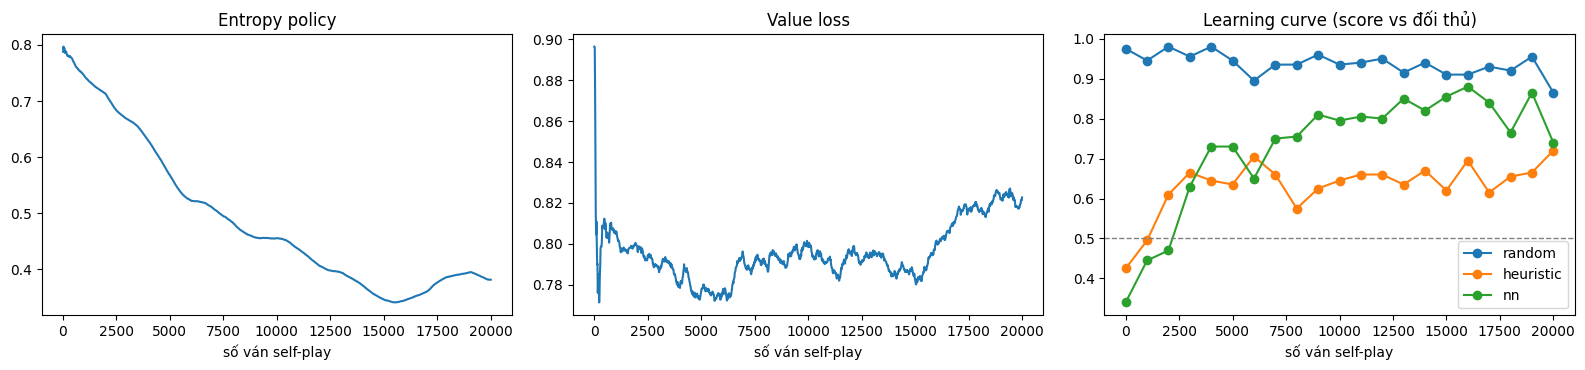

[eval @ 20000] random: 0.865 | heuristic: 0.720 | nn: 0.740
Xong 20000 ván self-play trong 1939s


In [6]:
train_rows, curve_rows = [], []
LOG_DIR.mkdir(parents=True, exist_ok=True)


def run_eval(done):
    for opp in opponents:
        r = evaluate_vs(model, opp, EVAL_GAMES, EVAL_SEED_BASE)
        curve_rows.append({"episodes": done, "opponent": opp, **r})
    pd.DataFrame(curve_rows).to_csv(LOG_DIR / "learning_curve.csv", index=False)    # ghi dần: kernel chết cũng không mất log


def save(path, done):
    save_checkpoint(path, model, meta={"kind": "rl_selfplay", "seed": SEED, "episodes": done, "init_from": init_desc,
                                       "init_label_source": init_meta.get("label_source"), "train_config": cfg})


t0 = time.perf_counter()
done, next_eval, next_ckpt = 0, 0, CKPT_EVERY
while True:
    while next_eval <= done and next_eval <= EPISODES:       # lần đầu: đánh giá mạng CHƯA train RL (episode 0)
        run_eval(next_eval)
        next_eval += EVAL_EVERY
        if train_rows:
            show_progress(pd.DataFrame(train_rows), pd.DataFrame(curve_rows))
        last = [r for r in curve_rows if r["episodes"] == done]
        print(f"[eval @ {done}] " + " | ".join(f"{r['opponent']}: {r['score']:.3f}" for r in last), flush=True)
    while next_ckpt <= done:
        save(CKPT_PATH.parent / "rl_periodic" / f"rl_ep{next_ckpt:06d}.pt", done)
        next_ckpt += CKPT_EVERY
    if done >= EPISODES:
        break
    n = min(EPISODES_PER_UPDATE, EPISODES - done)
    batch, sp = self_play_batch(model, n, OPENING_PLIES, TEMPERATURE, rng, gen, DEVICE, REWARD, GAMMA)
    done += n
    if batch is None:
        continue
    st = policy_gradient_update(model, opt, batch, tcfg.get("normalize_advantage", True),
                                float(tcfg.get("value_loss_coef", 0.5)), float(tcfg.get("grad_clip", 1.0)), ENTROPY_COEF)
    train_rows.append({"episodes": done, **st, **sp})
    pd.DataFrame(train_rows).to_csv(LOG_DIR / "train_log.csv", index=False)
train_seconds = time.perf_counter() - t0
print(f"Xong {done} ván self-play trong {train_seconds:.0f}s")

## 6. Lưu checkpoint cuối và metadata
Checkpoint cuối = lần cập nhật cuối cùng (**không** chọn "tốt nhất" theo đối thủ để tránh thiên lệch chọn lọc).
Checkpoint định kỳ nằm ở `checkpoints/rl_periodic/`.

In [7]:
save(CKPT_PATH, done)
with open(LOG_DIR / "meta.json", "w", encoding="utf-8") as f:
    json.dump({"seed": SEED, "episodes": done, "init_from": init_desc,
               "init_label_source": init_meta.get("label_source"), "opponents_used": opponents,
               "opponents_skipped": skipped, "eval_games": EVAL_GAMES, "device": str(DEVICE),
               "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
               "cpu": platform.processor() or platform.machine(), "torch": torch.__version__,
               "train_seconds": round(train_seconds, 1), "n_params": count_params(model), "config": cfg},
              f, ensure_ascii=False, indent=2)
print(f"Checkpoint cuối: {CKPT_PATH}\nLog: {LOG_DIR}")
if skipped:
    print("LƯU Ý khi viết báo cáo: các đối thủ này đã bị bỏ qua lúc đánh giá:", skipped)

Checkpoint cuối: c:\Users\ACER\Documents\CODING\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\checkpoints\rl_selfplay_heuristic.pt
Log: c:\Users\ACER\Documents\CODING\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\results\logs\train_rl_heuristic\rl_seed42


## 7. Learning curve cuối cùng
Bảng điểm xuất phát (episode 0) so với điểm cuối. **Cẩn thận khi đọc**: mỗi điểm chỉ có `EVAL_GAMES` ván nên dao động nhiều (xem khoảng tin cậy ở notebook 03).
Kết luận cho câu hỏi 3 chỉ viết sau khi có kết quả chính thức từ giải đấu.

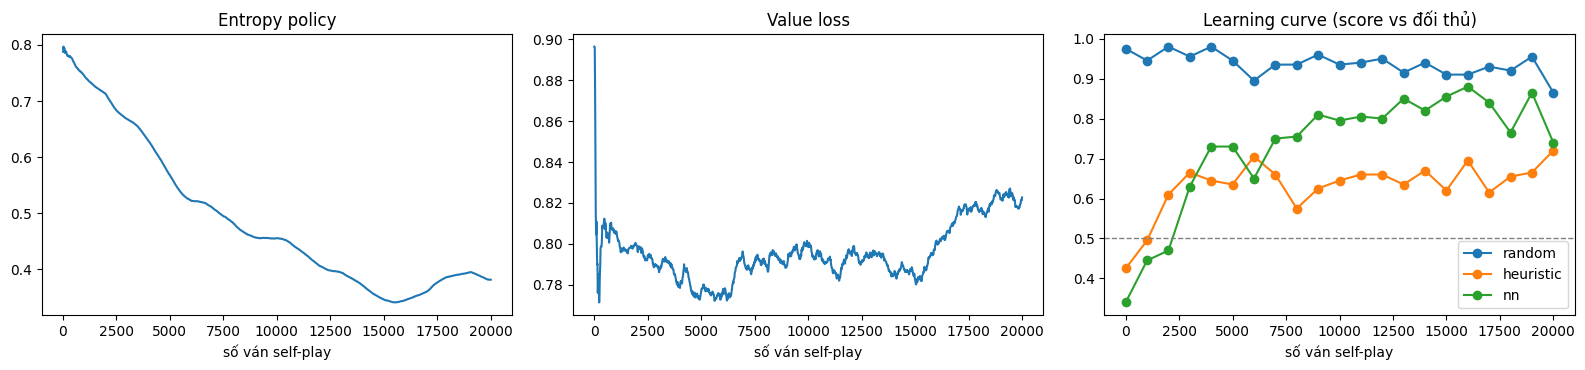

In [8]:
curve = pd.DataFrame(curve_rows)
first, last_ep = curve.episodes.min(), curve.episodes.max()
summary = curve[curve.episodes.isin([first, last_ep])].pivot(index="opponent", columns="episodes", values="score")
summary["thay đổi"] = summary[last_ep] - summary[first]
display(summary.round(3))
show_progress(pd.DataFrame(train_rows), curve)